# Practical Assignment 5: Ensemble Learning and Performance Evaluation

**Customer Churn Prediction using Stacking, AdaBoost and Voting Ensembles**

| | |
|---|---|
| **Name** | Tushar Kaldate |
| **Roll No.** | 47 |
| **Batch** | A2 |
| **PRN** | 202401040191 |
| **GitHub Repo** | [https://github.com/tusharkkp/AI-ML/](https://github.com/tusharkkp/AI-ML/) |
| **Selected Instance** | Customer Churn Prediction |

## Aim

To implement and compare **Stacking**, **AdaBoost** and **Voting** ensemble classifiers on a Customer Churn Prediction problem, and to evaluate them against individual (base) machine learning models using appropriate classification metrics.

## Experiment Objectives

1. Implement a **stacking ensemble** that uses a meta-classifier to combine the predictions of several base classifiers.
2. Implement an **AdaBoost ensemble** using chosen base classifiers (decision stump, shallow tree, logistic regression).
3. Implement a **voting ensemble** (hard / majority voting, plus soft voting for comparison).
4. Compare ensembles and base models using Accuracy, Precision, Recall, F1-score, ROC-AUC, confusion matrices and cross-validation.
5. Summarise findings, explain when each ensemble method should be used, and suggest further improvements.

## Experiment Outcome

After completing this experiment, the student will be able to:

- Explain how bagging, boosting and stacking differ and why combining models can reduce variance and/or bias.
- Build stacking, AdaBoost and voting classifiers using scikit-learn pipelines on a churn dataset.
- Choose suitable metrics for an **imbalanced** classification problem (Recall, F1, ROC-AUC rather than accuracy alone).
- Interpret the comparison and decide which ensemble technique suits a given business problem.

## Conceptual Details

### 1. What is Ensemble Learning?
Ensemble learning combines several models (*base learners*) so that the final prediction is more accurate and more robust than that of any single model. The three main families are **Bagging**, **Boosting** and **Stacking**.

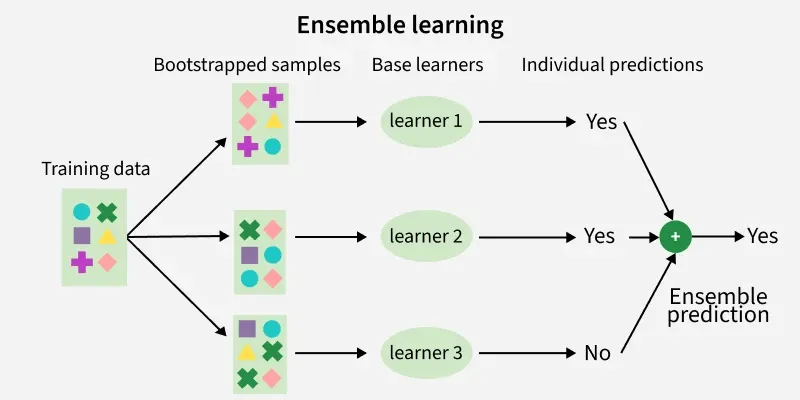

*Figure 1: Ensemble learning - bootstrapped samples, base learners and the combined prediction*

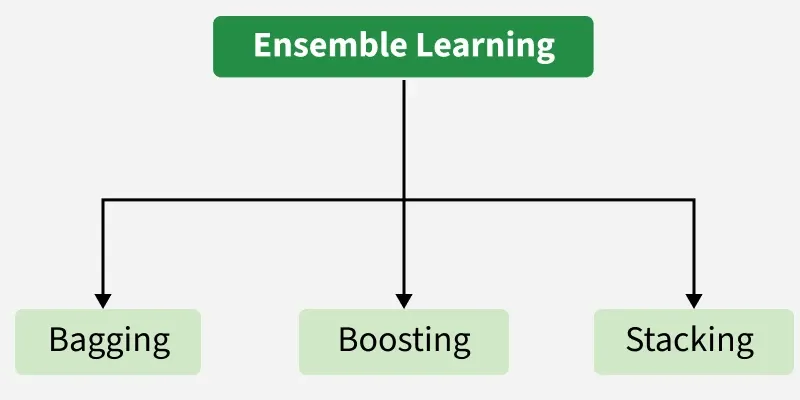

*Figure 2: Main families of ensemble learning - Bagging, Boosting and Stacking*

### 2. Bagging (Bootstrap Aggregating)
- Each base model is trained **in parallel** on a different bootstrap sample of the training data.
- Final prediction = majority vote (classification) or average (regression).
- Mainly reduces **variance** (e.g. Random Forest).

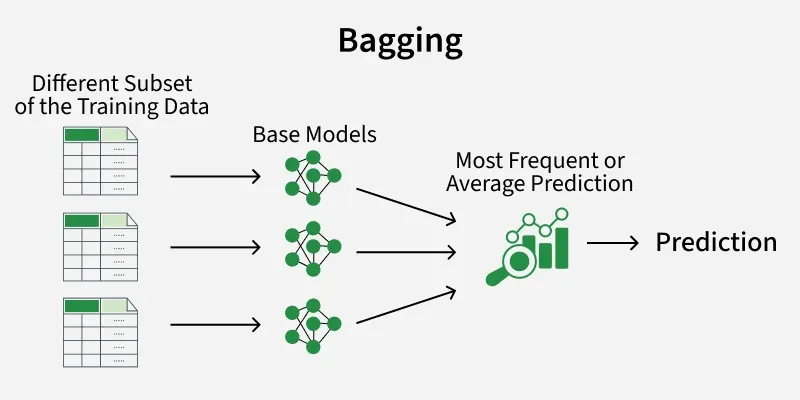

*Figure 3: Bagging - base models trained in parallel on different subsets, results averaged or voted*

### 3. Boosting
- Base models are trained **sequentially**; each new model focuses on the mistakes of the previous ones.
- Mainly reduces **bias** (e.g. AdaBoost, Gradient Boosting, XGBoost).
- **AdaBoost**: starts with equal sample weights $w_i = 1/N$. After each weak learner $h_t$:
  - weighted error: $\epsilon_t = \sum_i w_i \, \mathbb{1}[h_t(x_i) \neq y_i]$
  - learner weight: $\alpha_t = \tfrac{1}{2}\ln\frac{1-\epsilon_t}{\epsilon_t}$
  - misclassified samples get their weight increased: $w_i \leftarrow w_i\, e^{\alpha_t}$, correct ones decreased, then weights are normalised.
  - final model: $H(x) = \mathrm{sign}\left(\sum_t \alpha_t h_t(x)\right)$

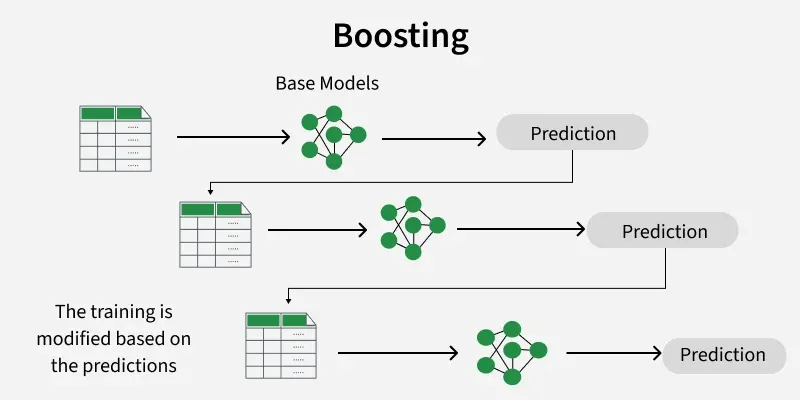

*Figure 4: Boosting - models trained sequentially, training modified using previous predictions*

### 4. Stacking (Stacked Generalisation)
- Different kinds of base models (e.g. Logistic Regression, KNN, Decision Tree, SVM, Naive Bayes) are trained on the data.
- Their **out-of-fold predicted probabilities** become the input features of a **meta-learner** (here Logistic Regression), which learns how to best combine them.
- Out-of-fold predictions (via cross-validation) are used so the meta-learner does not see predictions made on data the base models were trained on (avoids leakage).

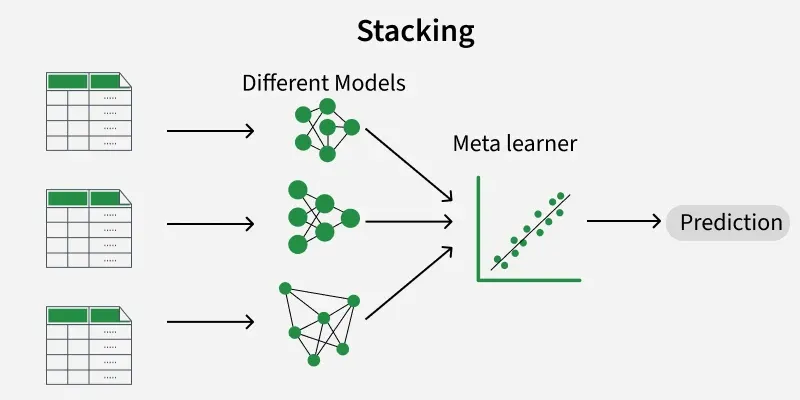

*Figure 5: Stacking - different base models feed a meta-learner*

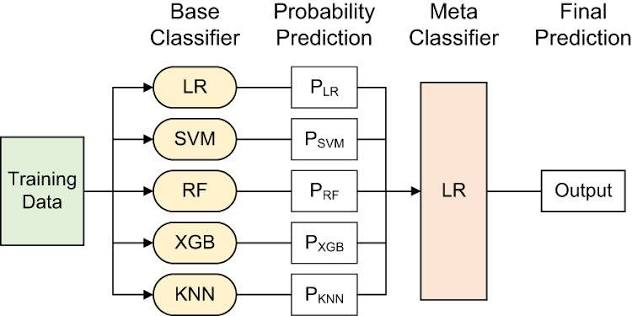

*Figure 6: Example stacking pipeline - LR, SVM, RF, XGB, KNN base classifiers with a Logistic Regression meta-classifier*

### 5. Voting
- **Hard voting**: each model casts one vote for a class, the majority wins.
- **Soft voting**: the predicted class probabilities are averaged and the largest wins.
- No training of a meta-model, so it is simple, but it treats every model's opinion equally (unless weights are set).

### 6. Evaluation metrics for churn
Churn data is usually **imbalanced** (only ~25-30% of customers leave), so accuracy alone is misleading.

| Metric | Meaning in churn context |
|---|---|
| Precision | Of customers predicted to churn, how many really churn |
| Recall | Of customers who really churn, how many we catch (very important: a missed churner is lost revenue) |
| F1-score | Harmonic mean of precision and recall |
| ROC-AUC | Ranking quality across all thresholds |

## Algorithm / Flowchart

```text
                    +--------------------------+
                    |  Load Customer Churn data|
                    +------------+-------------+
                                 |
                    +------------v-------------+
                    | Clean + encode + scale   |
                    | (ColumnTransformer)      |
                    +------------+-------------+
                                 |
                    +------------v-------------+
                    | Stratified train/test    |
                    | split (80 / 20)          |
                    +------------+-------------+
                                 |
        +------------------------+------------------------+
        |                        |                        |
+-------v--------+     +---------v--------+     +---------v--------+
| STACKING       |     | ADABOOST         |     | VOTING           |
| base: LR,KNN,  |     | base: stump,     |     | base: LR,KNN,DT, |
| DT,SVM,NB      |     | depth-2 tree, LR |     | SVM,NB           |
| meta: LR (5-CV)|     | sequential re-   |     | majority (hard)  |
|                |     | weighting        |     | + soft           |
+-------+--------+     +---------+--------+     +---------+--------+
        |                        |                        |
        +------------------------+------------------------+
                                 |
                    +------------v-------------+
                    | Evaluate on test set:    |
                    | Acc, Prec, Rec, F1, AUC, |
                    | confusion matrix, ROC,   |
                    | 5-fold CV F1             |
                    +------------+-------------+
                                 |
                    +------------v-------------+
                    | Compare, analyse, report |
                    +--------------------------+
```

**Stacking algorithm**
1. Split train set into K folds.
2. For each base model, train on K-1 folds and predict probabilities on the held-out fold; repeat so every training sample has an out-of-fold prediction.
3. Build a new feature matrix from these probabilities and train the meta-classifier on it.
4. Refit the base models on the full training set; at test time feed their probabilities to the meta-classifier.

**AdaBoost algorithm**
1. Initialise sample weights $w_i = 1/N$.
2. For $t = 1 \ldots T$: train weak learner on weighted data, compute error $\epsilon_t$, learner weight $\alpha_t$, update sample weights.
3. Predict with the weighted vote of all weak learners.

**Voting algorithm**
1. Train every base model independently on the full training set.
2. For each test sample collect all predictions; output the majority class (hard) or the class with the highest mean probability (soft).

## Python Code

### Step 1: Imports and setup

In [1]:
# =============================================================
# STEP 1: IMPORT LIBRARIES AND SET UP THE ENVIRONMENT
# =============================================================
import os, warnings, time               # os: file checks | warnings: hide noise | time: measure training time
import numpy as np                      # numerical arrays and random numbers
import pandas as pd                     # tabular data (DataFrames)
import matplotlib.pyplot as plt         # plotting
import seaborn as sns                   # nicer statistical plots

# --- data splitting and cross-validation utilities ---
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
# --- preprocessing: scaling numeric columns, encoding categorical columns ---
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer   # apply different transforms to different columns
from sklearn.pipeline import Pipeline           # chain preprocessing + model into one object

# --- base (individual) classifiers ---
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# --- the three ensemble methods required by the assignment ---
from sklearn.ensemble import StackingClassifier, AdaBoostClassifier, VotingClassifier

# --- evaluation metrics ---
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, classification_report)

warnings.filterwarnings("ignore")       # keep the notebook output clean
RANDOM_STATE = 42                       # fixed seed => results are reproducible
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")
print("Setup complete")

Setup complete


### Step 2: Load the Customer Churn dataset

The notebook first looks for the public **IBM / Kaggle "Telco Customer Churn"** file (`WA_Fn-UseC_-Telco-Customer-Churn.csv`) in the working folder. If it is present it is used directly.

If the file is not found (for example when the notebook is run in a fresh environment with no internet), the notebook generates a **synthetic Telco-style churn dataset** with the same column structure and realistic churn drivers (month-to-month contracts, fibre internet, short tenure, electronic-check payment, no tech support, etc.), so that every cell still runs end to end. The `DATA_SOURCE` variable tells you which one was used.

> To use the real data, download the CSV from Kaggle ("blastchar/telco-customer-churn") and place it next to this notebook.

In [2]:
# =============================================================
# STEP 2: LOAD THE CUSTOMER CHURN DATASET
# =============================================================

def make_synthetic_churn(n=5000, seed=42):
    """Generate a Telco-style churn dataset (used only if the real CSV is missing).

    Each customer gets random attributes; the churn label is then drawn from a
    logistic (sigmoid) function of those attributes, so that known factors such as
    month-to-month contracts or short tenure really do increase churn probability.
    """
    rng = np.random.default_rng(seed)                       # reproducible random generator

    # ---- customer attributes ----
    tenure   = rng.integers(1, 73, n)                       # months with the company (1-72)
    contract = rng.choice(["Month-to-month", "One year", "Two year"], n, p=[0.55, 0.21, 0.24])
    internet = rng.choice(["DSL", "Fiber optic", "No"], n, p=[0.34, 0.44, 0.22])
    payment  = rng.choice(["Electronic check", "Mailed check", "Bank transfer (automatic)",
                           "Credit card (automatic)"], n, p=[0.34, 0.23, 0.22, 0.21])
    senior    = rng.binomial(1, 0.16, n)                    # 1 = senior citizen
    paperless = rng.binomial(1, 0.60, n)                    # 1 = paperless billing
    gender    = rng.choice(["Male", "Female"], n)
    partner   = rng.choice(["Yes", "No"], n)
    # customers without internet cannot have tech support
    tech = np.where(internet == "No", "No internet service",
                    rng.choice(["Yes", "No"], n, p=[0.3, 0.7]))

    # ---- billing amounts depend on the internet service type ----
    monthly = (20 + 25 * (internet == "DSL") + 50 * (internet == "Fiber optic")
               + rng.normal(0, 6, n) + 4 * (tech == "Yes")).clip(18, 120)
    total = (monthly * tenure + rng.normal(0, 40, n)).clip(18, None)   # roughly monthly x tenure

    # ---- churn probability: positive weight => more churn, negative => less churn ----
    logit = (-1.9
             + 1.3  * (contract == "Month-to-month")        # flexible contract -> easy to leave
             - 1.1  * (contract == "Two year")              # long contract -> stays
             - 0.035 * tenure                               # long-term customers churn less
             + 0.9  * (internet == "Fiber optic")
             + 0.012 * (monthly - 65)                       # expensive plans churn more
             + 0.45 * senior + 0.3 * paperless
             + 0.55 * (payment == "Electronic check")
             - 0.6  * (tech == "Yes")                       # tech support helps retention
             - 0.2  * (partner == "Yes")
             + rng.normal(0, 0.9, n))                       # random noise (real data is never perfect)
    churn = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)   # sigmoid -> probability -> 0/1 label

    return pd.DataFrame({
        "gender": gender, "SeniorCitizen": senior, "Partner": partner, "tenure": tenure,
        "InternetService": internet, "TechSupport": tech, "Contract": contract,
        "PaperlessBilling": np.where(paperless == 1, "Yes", "No"), "PaymentMethod": payment,
        "MonthlyCharges": monthly.round(2), "TotalCharges": total.round(2),
        "Churn": np.where(churn == 1, "Yes", "No")})


REAL_FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"          # Kaggle Telco churn file name
if os.path.exists(REAL_FILE):
    # ---- real dataset found: load and clean it ----
    df = pd.read_csv(REAL_FILE)
    df = df.drop(columns=["customerID"])                    # ID column has no predictive value
    # TotalCharges is stored as text with blanks in the raw file -> convert to numbers
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())  # fill blanks with median
    DATA_SOURCE = "Real Telco Customer Churn CSV"
else:
    # ---- real file not found: fall back to the synthetic data ----
    df = make_synthetic_churn()
    DATA_SOURCE = "Synthetic Telco-style churn data (generated in notebook)"

print("Data source :", DATA_SOURCE)
print("Shape       :", df.shape)                             # (rows, columns)
df.head()                                                   # preview first 5 rows

Data source : Synthetic Telco-style churn data (generated in notebook)
Shape       : (5000, 12)


,gender,SeniorCitizen,Partner,tenure,InternetService,TechSupport,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,7,Fiber optic,No,Month-to-month,Yes,Bank transfer (automatic),71.48,451.10,No
1,Male,1,Yes,56,Fiber optic,No,One year,Yes,Electronic check,59.91,3344.85,No
2,Female,0,No,48,DSL,No,Two year,Yes,Electronic check,39.84,1909.18,No
3,Male,0,Yes,32,Fiber optic,No,Two year,No,Credit card (automatic),71.24,2246.37,No
4,Female,0,Yes,32,Fiber optic,No,Month-to-month,Yes,Bank transfer (automatic),61.85,2000.16,Yes


### Step 3: Exploratory data analysis

In [3]:
# =============================================================
# STEP 3: EXPLORATORY DATA ANALYSIS (EDA) - TEXT SUMMARY
# =============================================================
print(df.info())                                            # column names, data types, non-null counts
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])   # show only columns that have NaNs
print("\nChurn distribution:")
print(df["Churn"].value_counts())                           # counts of Yes / No
print((df["Churn"].value_counts(normalize=True) * 100).round(2))   # same as percentages -> shows class imbalance
df.describe()                                               # mean/std/min/max of numeric columns

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            5000 non-null   str    
 1   SeniorCitizen     5000 non-null   int64  
 2   Partner           5000 non-null   str    
 3   tenure            5000 non-null   int64  
 4   InternetService   5000 non-null   str    
 5   TechSupport       5000 non-null   str    
 6   Contract          5000 non-null   str    
 7   PaperlessBilling  5000 non-null   str    
 8   PaymentMethod     5000 non-null   str    
 9   MonthlyCharges    5000 non-null   float64
 10  TotalCharges      5000 non-null   float64
 11  Churn             5000 non-null   str    
dtypes: float64(2), int64(2), str(8)
memory usage: 468.9 KB
None

Missing values:
 Series([], dtype: int64)

Churn distribution:
Churn
No     4085
Yes     915
Name: count, dtype: int64
Churn
No     81.7
Yes    18.3
Name: proportion, dtype: float6

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.165800,36.407200,51.868718,1897.222086
std,0.371938,20.839776,20.229101,1385.332655
min,0.000000,1.000000,18.000000,18.000000
25%,0.000000,18.000000,37.617500,766.055000
50%,0.000000,36.000000,52.410000,1556.445000
75%,0.000000,55.000000,70.040000,2844.715000
max,1.000000,72.000000,95.960000,6184.850000


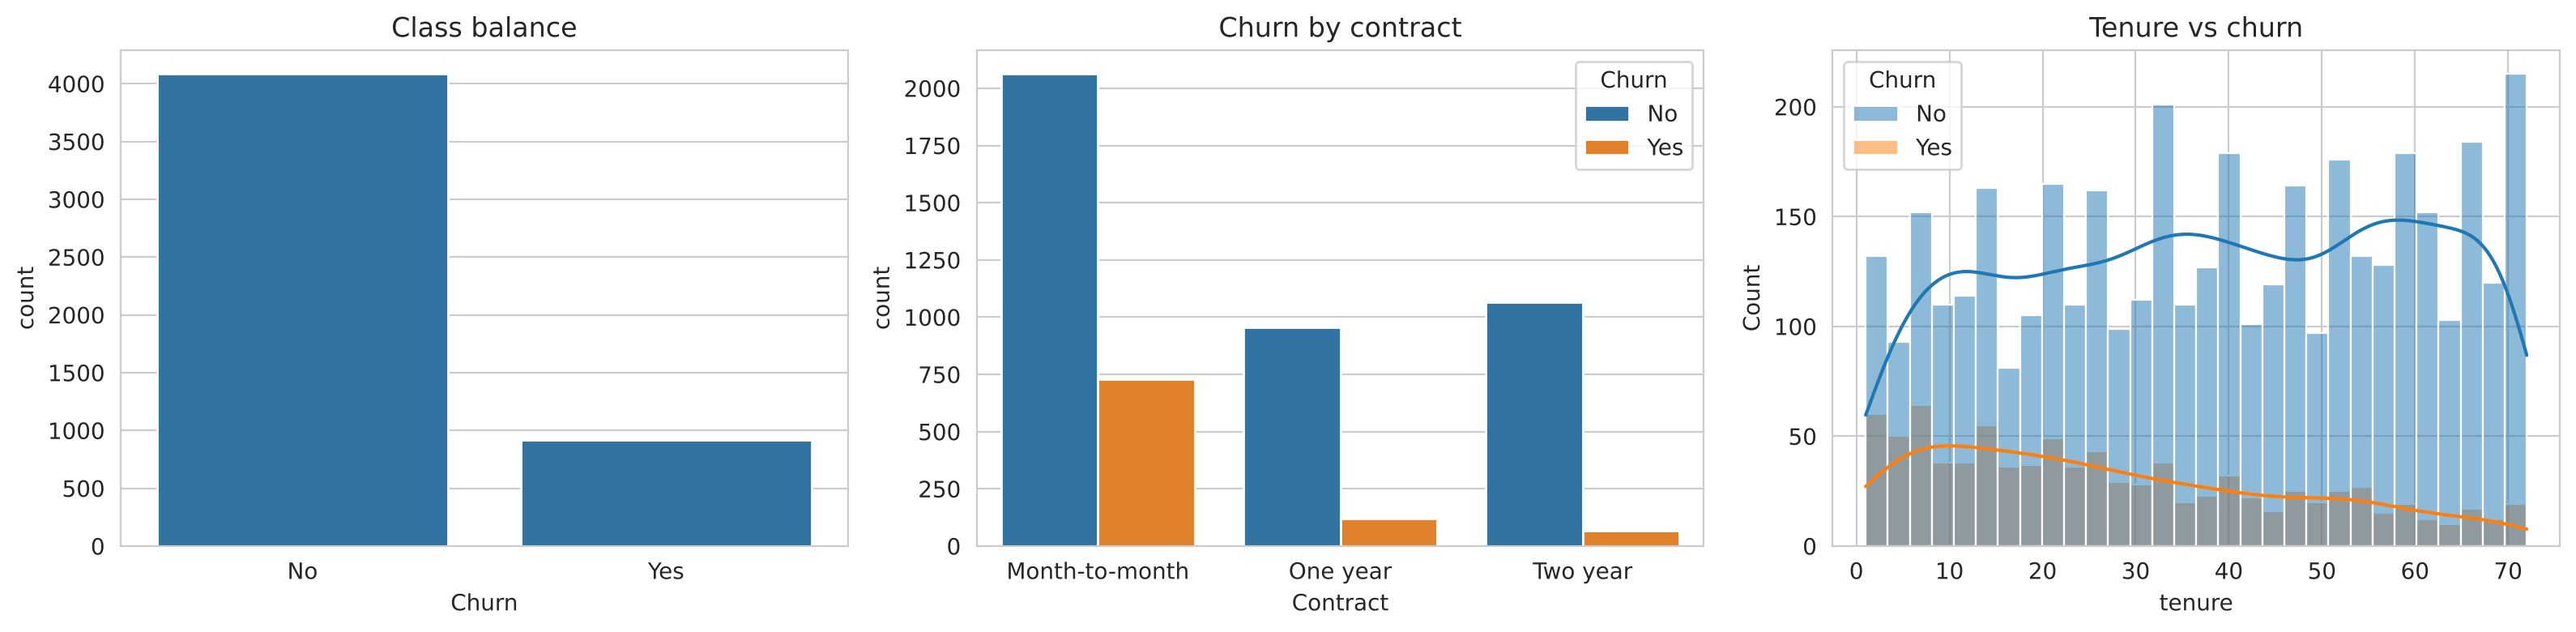

In [4]:
# =============================================================
# STEP 3 (continued): EDA - VISUALISATIONS
# =============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4))             # three plots side by side

sns.countplot(data=df, x="Churn", ax=axes[0])               # how imbalanced is the target?
axes[0].set_title("Class balance")

sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[1])   # does contract type affect churn?
axes[1].set_title("Churn by contract")

sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True, ax=axes[2])  # do new customers churn more?
axes[2].set_title("Tenure vs churn")

plt.tight_layout(); plt.show()

### Step 4: Preprocessing and train/test split

- Target: `Churn` (Yes = 1, No = 0).
- Numeric features are standardised (needed for KNN, SVM and Logistic Regression).
- Categorical features are one-hot encoded.
- A **stratified** 80/20 split keeps the churn ratio the same in train and test.

In [5]:
# =============================================================
# STEP 4: PREPROCESSING AND TRAIN / TEST SPLIT
# =============================================================
X = df.drop(columns=["Churn"])                              # input features
y = (df["Churn"] == "Yes").astype(int)                      # target: 1 = customer churned, 0 = stayed

# Separate columns by type because they need different preprocessing
num_cols = X.select_dtypes(include=["int64", "float64", "int32"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "string"]).columns.tolist()
print("Numeric    :", num_cols)
print("Categorical:", cat_cols)

# ColumnTransformer = apply the right transformation to each group of columns
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),                           # scale numbers (mean 0, std 1) - needed by KNN/SVM/LR
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])    # text categories -> 0/1 columns

# stratify=y keeps the same churn percentage in both train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("\nTrain:", X_train.shape, " Test:", X_test.shape)
print("Churn rate train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Numeric    : ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'Partner', 'InternetService', 'TechSupport', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Train: (4000, 11)  Test: (1000, 11)
Churn rate train: 0.183 | test: 0.183


### Step 5: Base classifiers

Five diverse base models are used (diversity is what makes ensembles work): a linear model, an instance-based model, a tree, a kernel model and a probabilistic model.

In [6]:
# =============================================================
# STEP 5: DEFINE THE BASE CLASSIFIERS
# =============================================================
# Five DIVERSE models are used - ensembles work best when the
# models make different kinds of mistakes.
def base_models():
    return {
        # linear model; class_weight="balanced" gives churners more importance (imbalanced data)
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
        # instance-based: looks at the 15 most similar customers
        "KNN":                 KNeighborsClassifier(n_neighbors=15),
        # shallow tree (depth 5) to avoid overfitting
        "Decision Tree":       DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE),
        # kernel model; probability=True is required so it can output probabilities for stacking/soft voting
        "SVM (RBF)":           SVC(kernel="rbf", C=1.0, probability=True, class_weight="balanced", random_state=RANDOM_STATE),
        # probabilistic model that assumes features are independent
        "Naive Bayes":         GaussianNB(),
    }

def make_pipe(clf):
    """Preprocessing + classifier in one object (prevents data leakage during cross-validation)."""
    return Pipeline([("prep", preprocessor), ("clf", clf)])

# GaussianNB cannot accept sparse matrices, so we convert the one-hot output to a dense array
from sklearn.preprocessing import FunctionTransformer
def make_pipe_dense(clf):
    return Pipeline([("prep", preprocessor),
                     ("dense", FunctionTransformer(lambda a: a.toarray() if hasattr(a, "toarray") else a)),
                     ("clf", clf)])

print(list(base_models().keys()))

['Logistic Regression', 'KNN', 'Decision Tree', 'SVM (RBF)', 'Naive Bayes']


### Step 6: Ensemble 1 - Stacking with a meta-classifier

Base learners: Logistic Regression, KNN, Decision Tree, SVM, Naive Bayes.
Meta-classifier: **Logistic Regression**, trained on the 5-fold out-of-fold probabilities (`cv=5`, `stack_method="predict_proba"`).

In [7]:
# =============================================================
# STEP 6: ENSEMBLE 1 - STACKING WITH A META-CLASSIFIER
# =============================================================
def build_stacking():
    # (name, model) pairs for every base learner
    estimators = [(name.replace(" ", "_"), clf) for name, clf in base_models().items()]

    stack = StackingClassifier(
        estimators=estimators,                              # LEVEL 0: the base classifiers
        # LEVEL 1: meta-classifier that learns how to combine the base predictions
        final_estimator=LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
        stack_method="predict_proba",                       # pass probabilities (not just labels) to the meta-classifier
        cv=5,                                               # out-of-fold predictions => avoids data leakage
        n_jobs=-1)                                          # use all CPU cores
    return make_pipe_dense(stack)

stacking_model = build_stacking()

### Step 7: Ensemble 2 - AdaBoost with different base classifiers

AdaBoost is run with three weak-learner choices:
1. **Decision stump** (depth 1) - the classic choice
2. **Depth-2 decision tree** - slightly stronger weak learner
3. **Logistic Regression** - to show AdaBoost works with any base estimator that supports sample weights

In [8]:
# =============================================================
# STEP 7: ENSEMBLE 2 - ADABOOST WITH DIFFERENT BASE CLASSIFIERS
# =============================================================
# AdaBoost trains weak learners one after another; after each round the weights of
# wrongly-classified customers are increased so the next learner focuses on them.
adaboost_models = {
    # (1) classic choice: decision stump = tree with only one split (very weak learner)
    "AdaBoost (Stump)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, class_weight="balanced"),
        n_estimators=200,          # number of boosting rounds
        learning_rate=0.5,         # shrinks each learner's contribution (smaller = more cautious)
        random_state=RANDOM_STATE),
    # (2) slightly stronger weak learner: tree with 2 levels
    "AdaBoost (Depth-2 Tree)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=2, class_weight="balanced"),
        n_estimators=150, learning_rate=0.5, random_state=RANDOM_STATE),
    # (3) AdaBoost works with any base model that supports sample weights, e.g. Logistic Regression
    "AdaBoost (Logistic Reg.)": AdaBoostClassifier(
        estimator=LogisticRegression(max_iter=1000, class_weight="balanced"),
        n_estimators=50, learning_rate=0.5, random_state=RANDOM_STATE),
}

### Step 8: Ensemble 3 - Voting (majority voting)

The same five base learners vote. **Hard voting** = majority vote of predicted classes (the one required by the assignment). **Soft voting** (average of probabilities) is added for comparison.

In [9]:
# =============================================================
# STEP 8: ENSEMBLE 3 - VOTING (MAJORITY VOTING)
# =============================================================
def build_voting(voting):
    # the same five base learners are used as voters
    estimators = [(name.replace(" ", "_"), clf) for name, clf in base_models().items()]
    # voting="hard": each model votes for a class, the MAJORITY wins
    # voting="soft": the predicted probabilities are averaged, the highest average wins
    return make_pipe_dense(VotingClassifier(estimators=estimators, voting=voting, n_jobs=-1))

voting_hard = build_voting("hard")    # majority voting (required by the assignment)
voting_soft = build_voting("soft")    # extra: probability averaging, for comparison

### Step 9: Train and evaluate everything

In [10]:
# =============================================================
# STEP 9: TRAIN AND EVALUATE EVERY MODEL ON THE TEST SET
# =============================================================
def evaluate(name, pipe, X_tr, y_tr, X_te, y_te):
    """Fit a model, predict on unseen test data and return all metrics."""
    t0 = time.time()
    pipe.fit(X_tr, y_tr)                                    # train on the training set only
    fit_time = time.time() - t0                             # how long training took

    y_pred = pipe.predict(X_te)                             # predicted class labels (0/1)

    # probability of churn (needed for ROC-AUC); hard voting cannot provide it
    try:
        y_score = pipe.predict_proba(X_te)[:, 1]
    except Exception:
        y_score = None
    auc = np.nan if y_score is None else roc_auc_score(y_te, y_score)

    return {
        "Model": name,
        "Accuracy":  accuracy_score(y_te, y_pred),                    # overall % correct
        "Precision": precision_score(y_te, y_pred, zero_division=0),  # of predicted churners, how many really churn
        "Recall":    recall_score(y_te, y_pred),                      # of real churners, how many we caught
        "F1-score":  f1_score(y_te, y_pred),                          # balance of precision and recall
        "ROC-AUC":   auc,                                             # ranking quality over all thresholds
        "Fit time (s)": fit_time}, y_pred, y_score

# ---- collect every model in one dictionary: 5 base + stacking + 3 AdaBoost + 2 voting ----
all_models = {}
for name, clf in base_models().items():
    all_models[name] = make_pipe_dense(clf)
all_models["Stacking (meta: LR)"] = stacking_model
for name, clf in adaboost_models.items():
    all_models[name] = make_pipe_dense(clf)
all_models["Voting (Hard / Majority)"] = voting_hard
all_models["Voting (Soft)"] = voting_soft

# ---- train + evaluate each one; keep predictions and scores for the plots later ----
rows, preds, scores = [], {}, {}
for name, pipe in all_models.items():
    r, p, s = evaluate(name, pipe, X_train, y_train, X_test, y_test)
    rows.append(r); preds[name] = p; scores[name] = s
    print(f"done: {name:28s} F1={r['F1-score']:.3f}  AUC={r['ROC-AUC']:.3f}")

results = pd.DataFrame(rows).set_index("Model")             # one row per model
results

done: Logistic Regression          F1=0.436  AUC=0.760


done: KNN                          F1=0.260  AUC=0.715


done: Decision Tree                F1=0.436  AUC=0.736


done: SVM (RBF)                    F1=0.439  AUC=0.751
done: Naive Bayes                  F1=0.422  AUC=0.714


done: Stacking (meta: LR)          F1=0.434  AUC=0.760
done: AdaBoost (Stump)             F1=0.354  AUC=0.668
done: AdaBoost (Depth-2 Tree)      F1=0.391  AUC=0.682
done: AdaBoost (Logistic Reg.)     F1=0.420  AUC=0.718


done: Voting (Hard / Majority)     F1=0.442  AUC=nan


done: Voting (Soft)                F1=0.435  AUC=0.751


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Fit time (s)
Model,,,,,,
Logistic Regression,0.672,0.318296,0.693989,0.436426,0.759904,0.032588
KNN,0.818,0.507937,0.174863,0.260163,0.715426,0.013385
Decision Tree,0.648,0.308390,0.743169,0.435897,0.735882,0.021470
SVM (RBF),0.683,0.324607,0.677596,0.438938,0.750607,2.153956
Naive Bayes,0.729,0.346154,0.540984,0.422175,0.713774,0.014439
Stacking (meta: LR),0.671,0.316583,0.688525,0.433735,0.760245,7.440229
AdaBoost (Stump),0.584,0.247289,0.622951,0.354037,0.667777,0.030672
AdaBoost (Depth-2 Tree),0.735,0.337302,0.464481,0.390805,0.681860,0.029258
AdaBoost (Logistic Reg.),0.672,0.310705,0.650273,0.420495,0.718158,0.059296


### Step 10: Comparison table (sorted by F1-score)

In [11]:
# =============================================================
# STEP 10: COMPARISON TABLE (SORTED BY F1-SCORE)
# =============================================================
styled = (results.sort_values("F1-score", ascending=False)          # best model on top
          .style.format("{:.4f}")                                   # 4 decimal places
          .background_gradient(cmap="Greens",                       # darker green = higher score
                               subset=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]))
styled

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Fit time (s)
Model,,,,,,
Voting (Hard / Majority),0.7020,0.3362,0.6448,0.4419,nan,2.3408
SVM (RBF),0.6830,0.3246,0.6776,0.4389,0.7506,2.1540
Logistic Regression,0.6720,0.3183,0.6940,0.4364,0.7599,0.0326
Decision Tree,0.6480,0.3084,0.7432,0.4359,0.7359,0.0215
Voting (Soft),0.7710,0.3964,0.4809,0.4346,0.7514,2.1907
Stacking (meta: LR),0.6710,0.3166,0.6885,0.4337,0.7602,7.4402
Naive Bayes,0.7290,0.3462,0.5410,0.4222,0.7138,0.0144
AdaBoost (Logistic Reg.),0.6720,0.3107,0.6503,0.4205,0.7182,0.0593
AdaBoost (Depth-2 Tree),0.7350,0.3373,0.4645,0.3908,0.6819,0.0293


### Step 11: 5-fold stratified cross-validation (F1 and ROC-AUC on the training set)

In [12]:
# =============================================================
# STEP 11: 5-FOLD STRATIFIED CROSS-VALIDATION
# =============================================================
# A single train/test split can be lucky or unlucky. Cross-validation repeats the
# evaluation on 5 different splits and reports mean and std for a more reliable comparison.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipe in all_models.items():
    f1s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)   # F1 on each fold
    if name == "Voting (Hard / Majority)":
        aucs = np.array([np.nan])                           # hard voting has no probabilities -> no AUC
    else:
        aucs = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_rows.append({"Model": name, "CV F1 mean": f1s.mean(), "CV F1 std": f1s.std(),
                    "CV AUC mean": np.nanmean(aucs)})
cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results.sort_values("CV F1 mean", ascending=False).round(4)

,CV F1 mean,CV F1 std,CV AUC mean
Model,,,
Voting (Hard / Majority),0.4719,0.0181,NaN
Stacking (meta: LR),0.4708,0.0168,0.7810
Logistic Regression,0.4693,0.0160,0.7809
Voting (Soft),0.4639,0.0371,0.7739
SVM (RBF),0.4622,0.0164,0.7567
Naive Bayes,0.4577,0.0278,0.7574
AdaBoost (Logistic Reg.),0.4514,0.0102,0.7416
Decision Tree,0.4418,0.0084,0.7461
AdaBoost (Depth-2 Tree),0.4311,0.0305,0.7381


### Step 12: Visual comparison

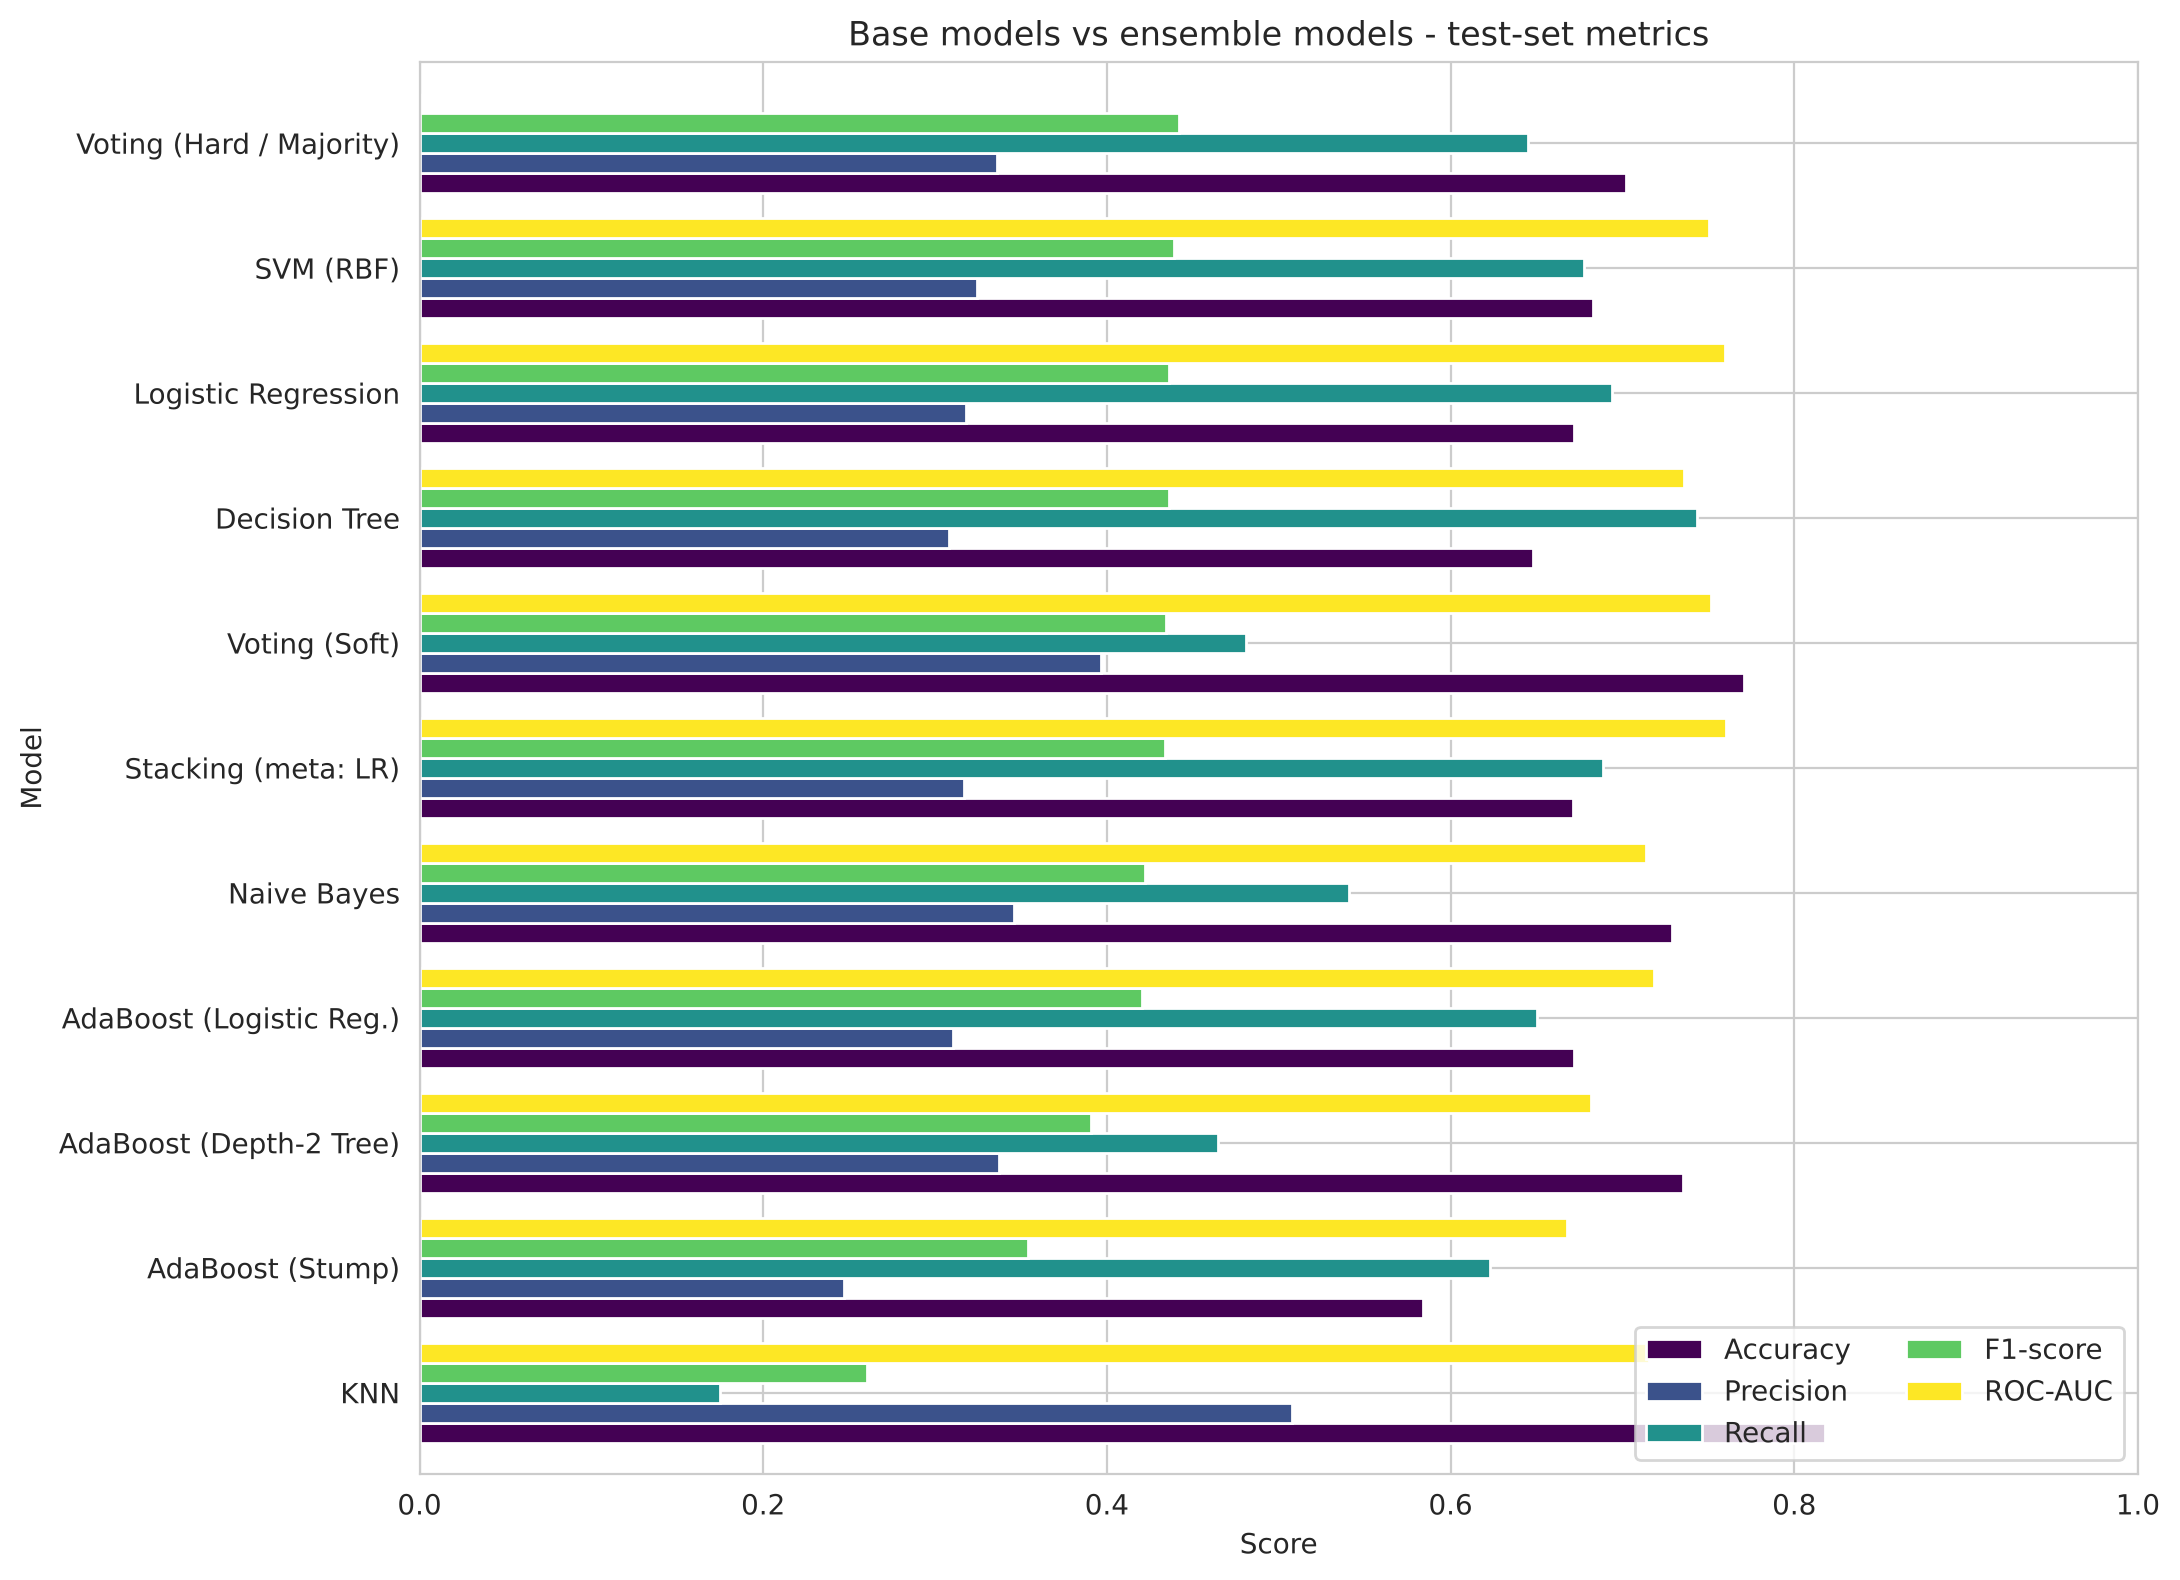

In [13]:
# =============================================================
# STEP 12: VISUAL COMPARISON - METRIC BAR CHART
# =============================================================
metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
plot_df = results[metrics].sort_values("F1-score")          # sort so the best model appears at the top
ax = plot_df.plot(kind="barh", figsize=(11, 8), width=0.8, colormap="viridis")
ax.set_title("Base models vs ensemble models - test-set metrics")
ax.set_xlabel("Score"); ax.set_xlim(0, 1)
ax.legend(loc="lower right", ncol=2)
plt.tight_layout(); plt.show()

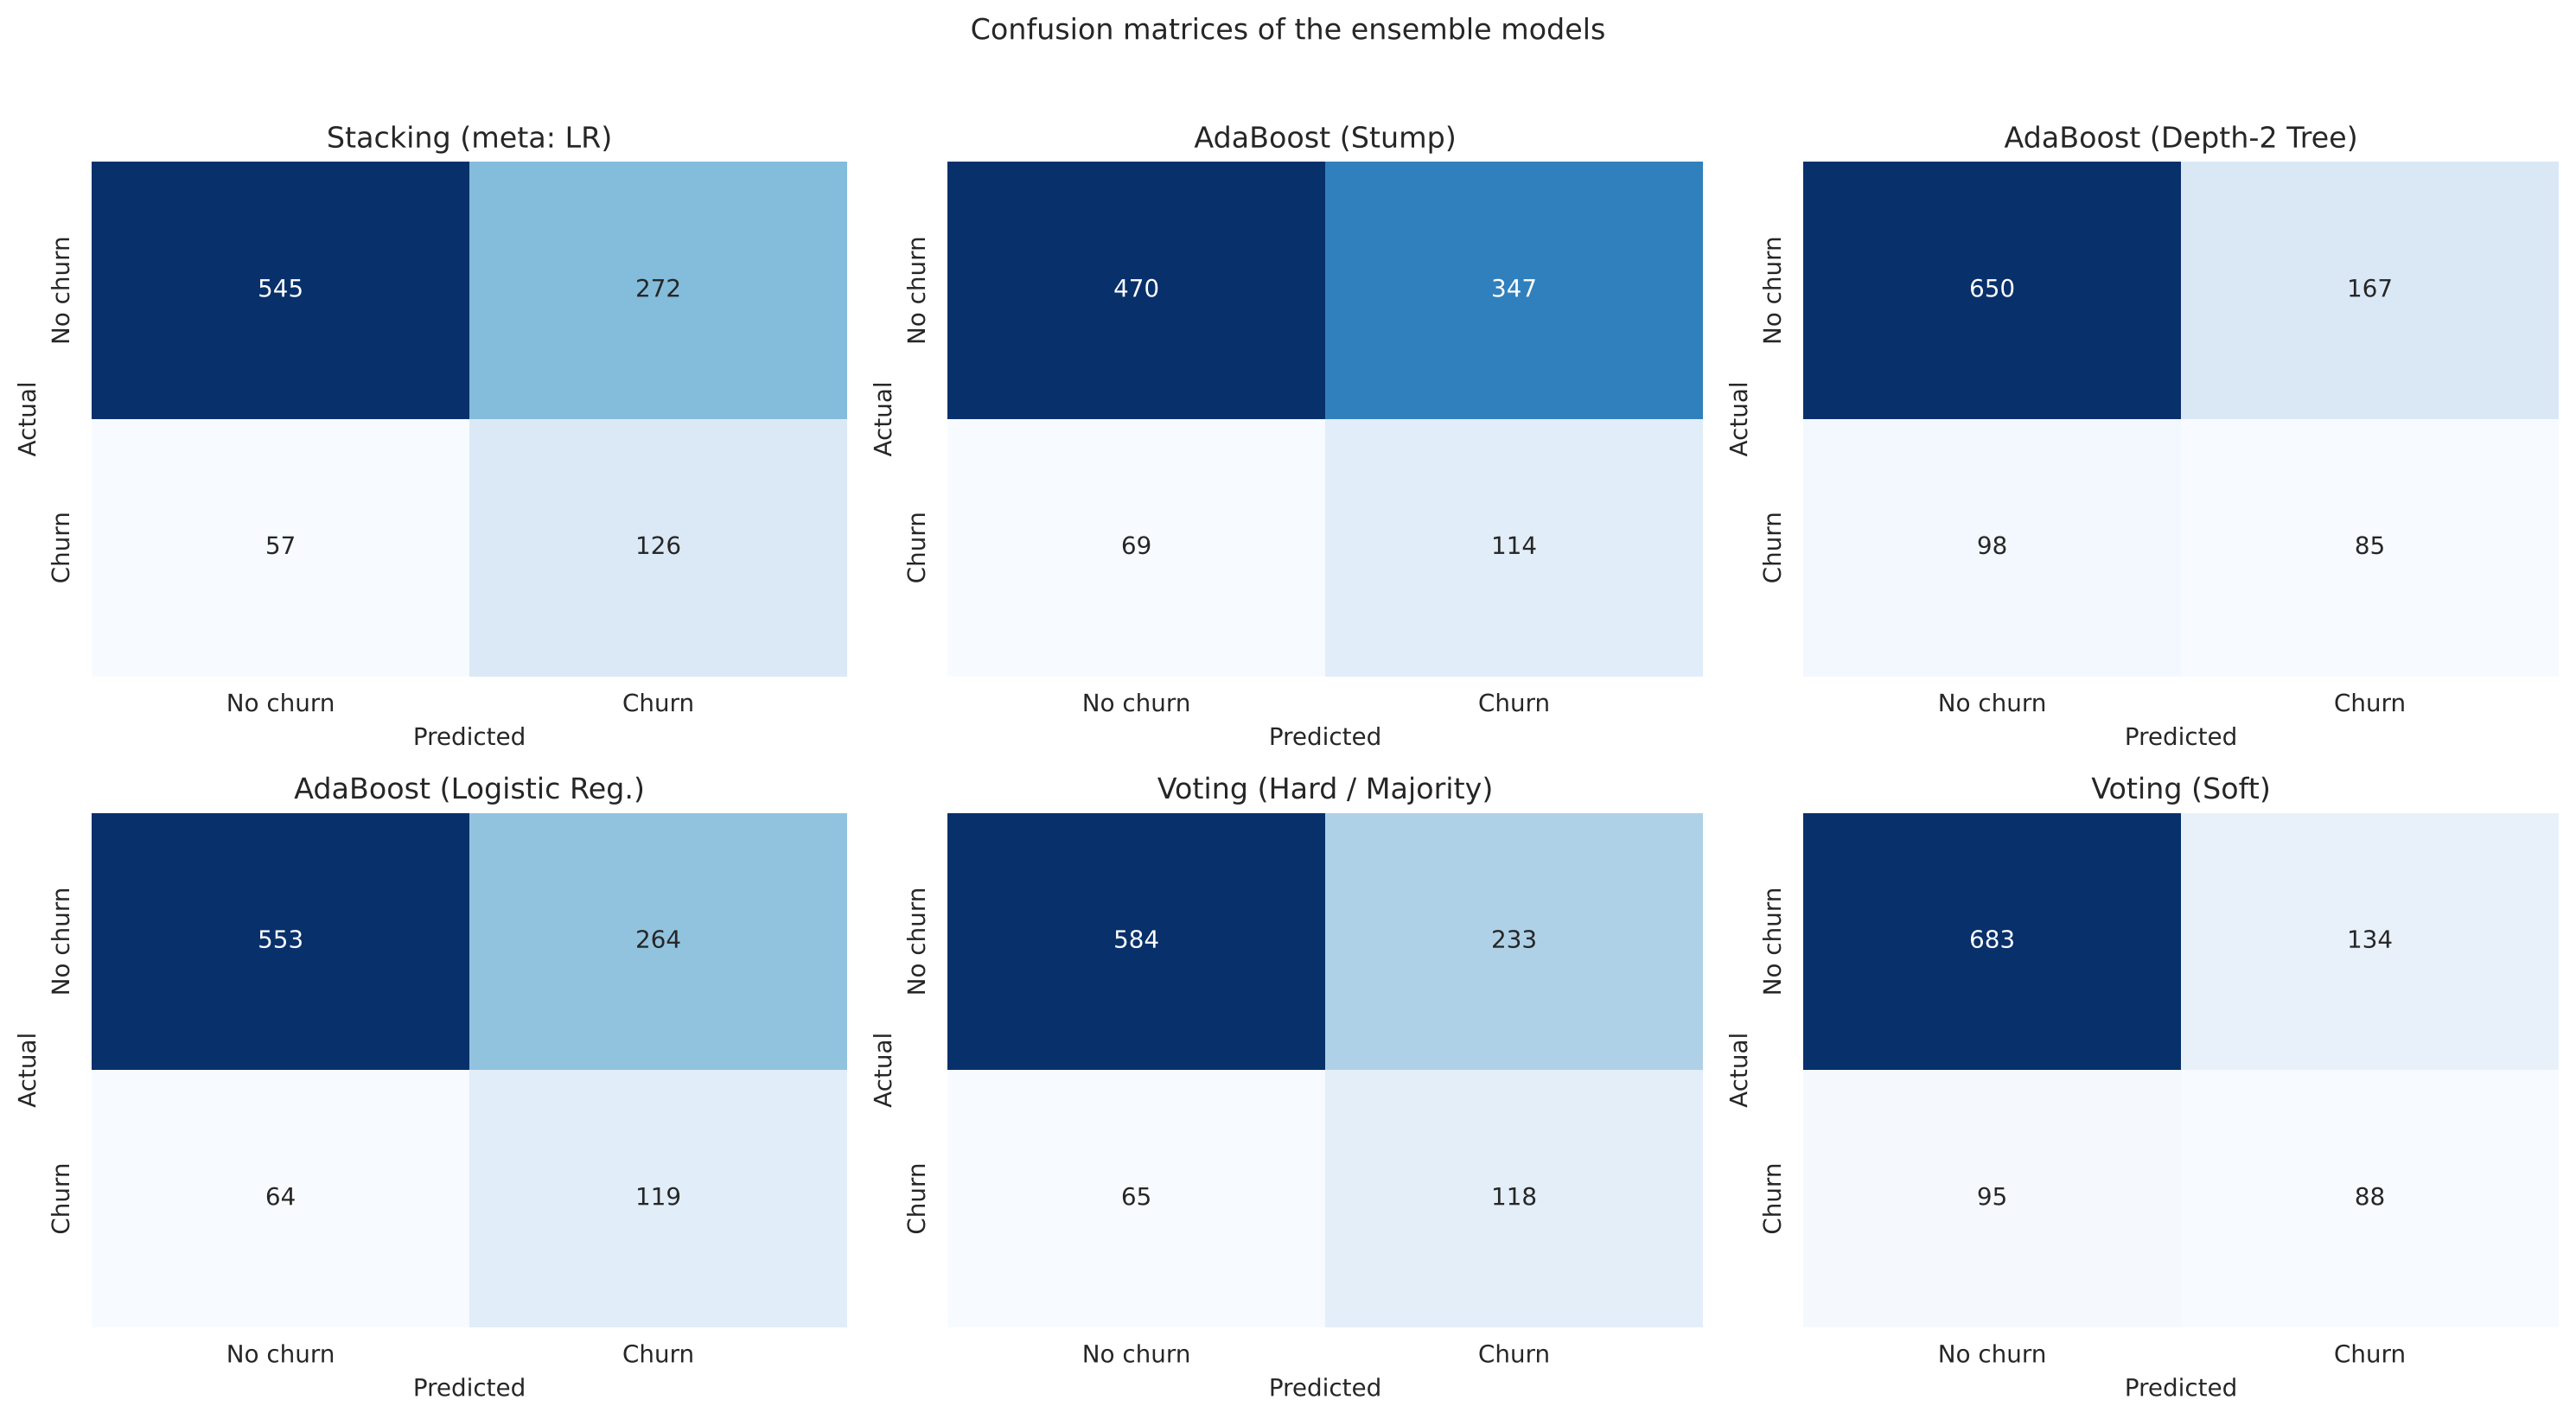

In [14]:
# =============================================================
# STEP 12 (continued): CONFUSION MATRICES OF THE ENSEMBLES
# =============================================================
# Rows = actual class, columns = predicted class.
# Bottom-right = churners correctly caught, bottom-left = churners missed (most costly error).
ensemble_names = ["Stacking (meta: LR)", "AdaBoost (Stump)", "AdaBoost (Depth-2 Tree)",
                  "AdaBoost (Logistic Reg.)", "Voting (Hard / Majority)", "Voting (Soft)"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, name in zip(axes.ravel(), ensemble_names):
    cm = confusion_matrix(y_test, preds[name])              # 2x2 table of TN, FP, FN, TP
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No churn", "Churn"], yticklabels=["No churn", "Churn"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.suptitle("Confusion matrices of the ensemble models", y=1.02)
plt.tight_layout(); plt.show()

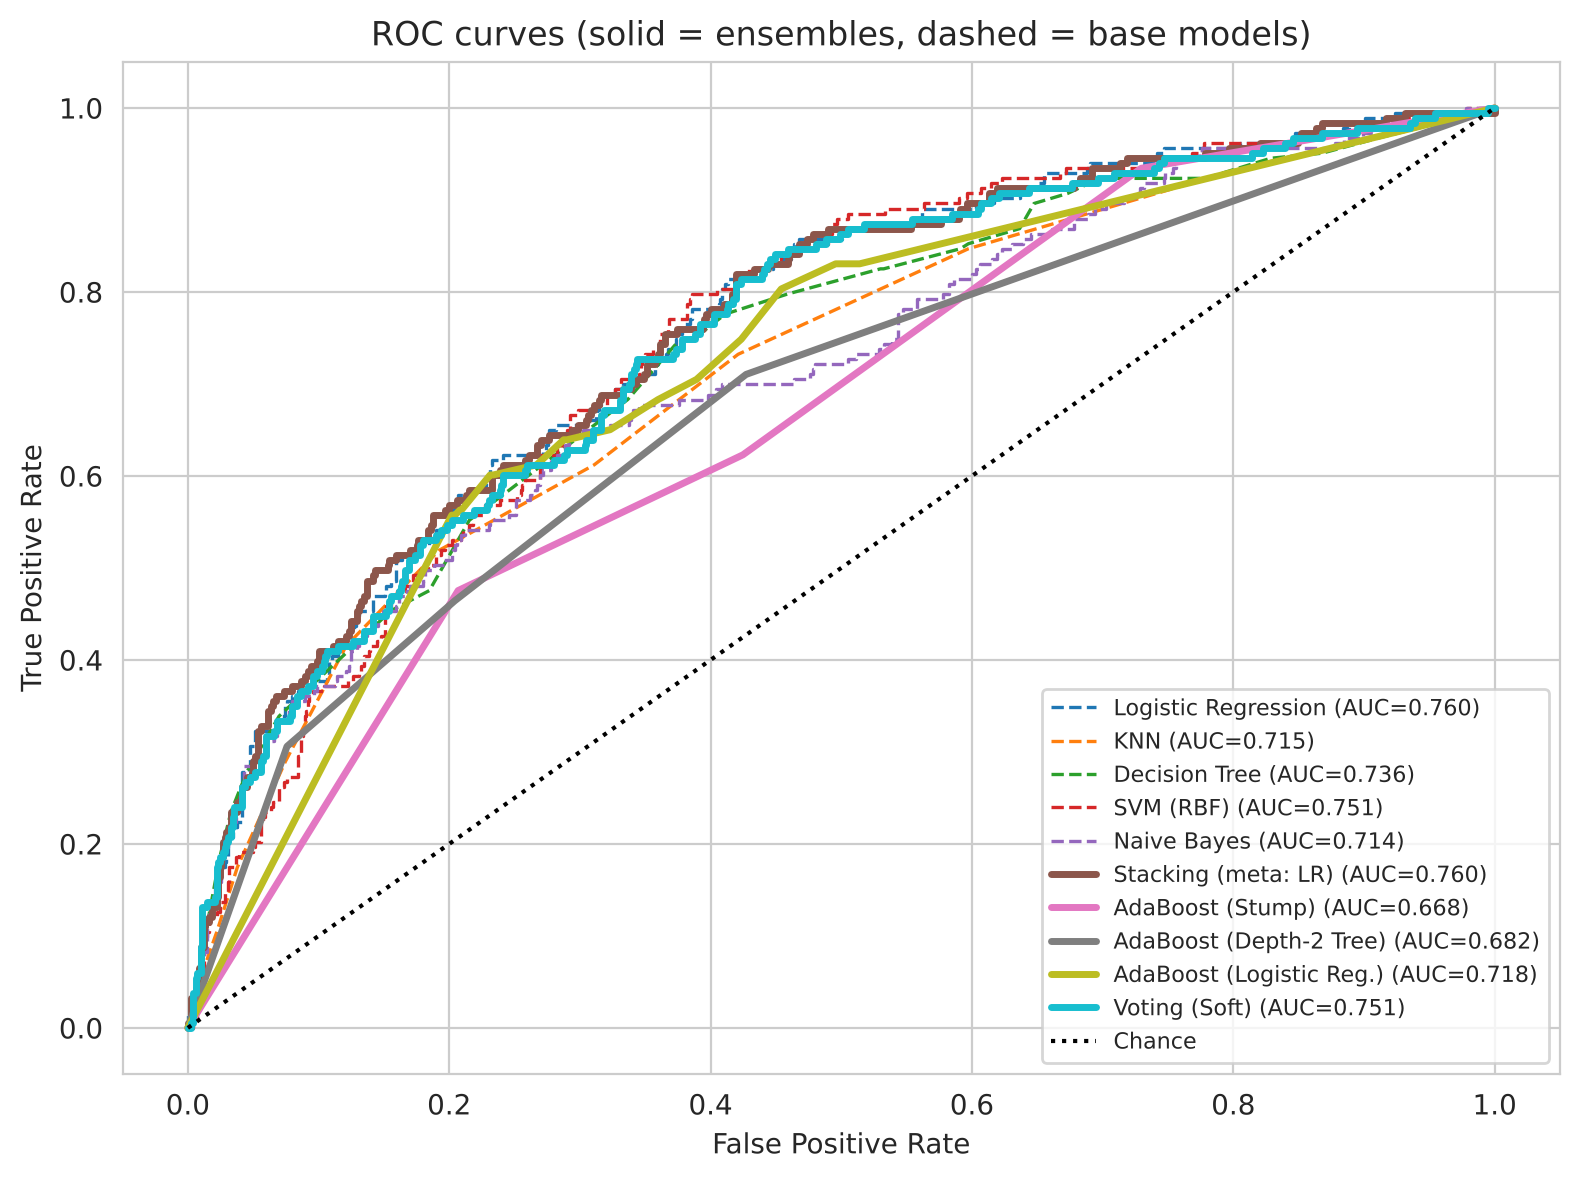

In [15]:
# =============================================================
# STEP 12 (continued): ROC CURVES
# =============================================================
# ROC curve: true-positive rate vs false-positive rate at every possible threshold.
# A curve closer to the top-left corner = better model.
plt.figure(figsize=(8, 6))
for name, s in scores.items():
    if s is None: continue                                  # skip hard voting (no probabilities)
    fpr, tpr, _ = roc_curve(y_test, s)
    lw = 2.5 if name in ensemble_names else 1.2             # ensembles: thick solid lines
    ls = "-" if name in ensemble_names else "--"            # base models: thin dashed lines
    plt.plot(fpr, tpr, lw=lw, ls=ls, label=f"{name} (AUC={roc_auc_score(y_test, s):.3f})")
plt.plot([0, 1], [0, 1], "k:", label="Chance")              # diagonal = random guessing
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves (solid = ensembles, dashed = base models)")
plt.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

### Step 13: Extra analysis - AdaBoost behaviour and stacking meta-learner weights

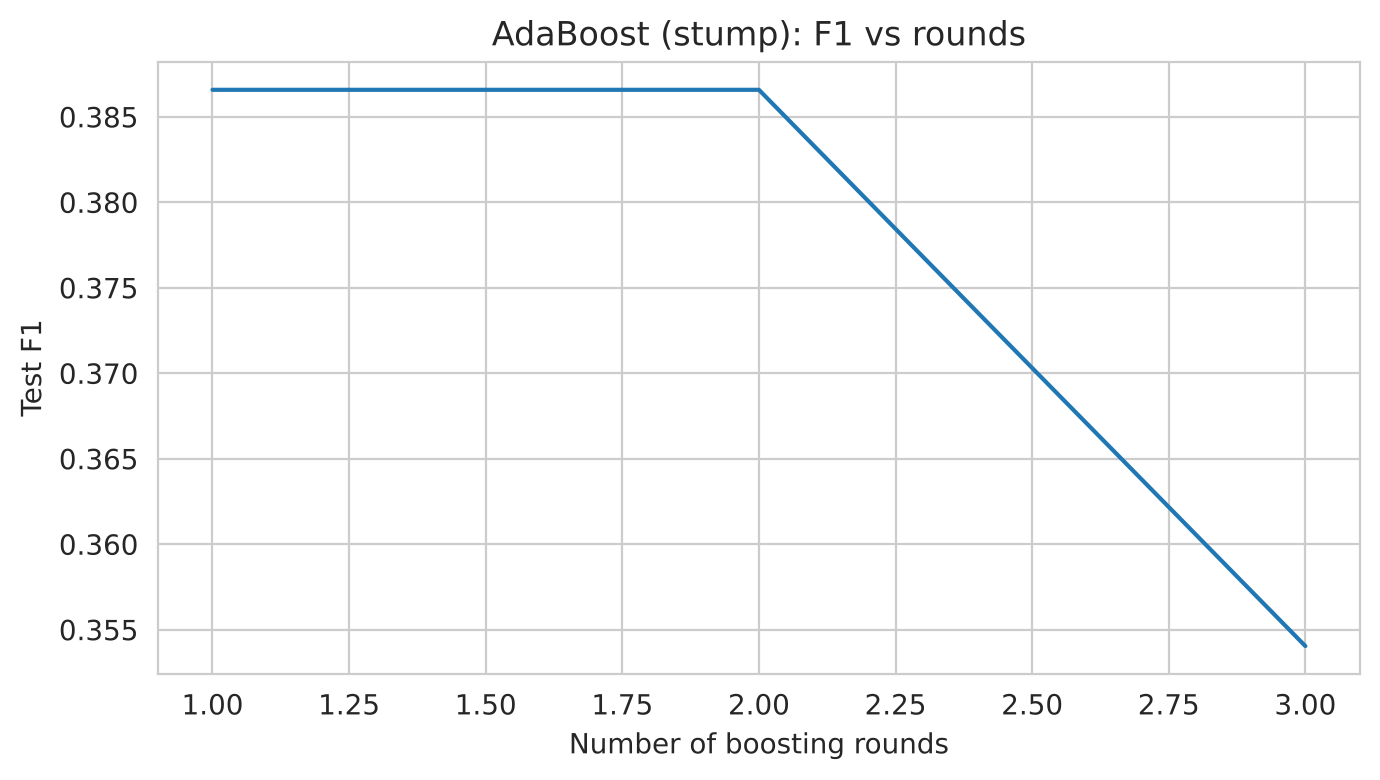

Meta-learner (Logistic Regression) coefficients on base-model probabilities:
Naive_Bayes           -0.023
SVM_(RBF)              0.017
KNN                    0.204
Decision_Tree          0.743
Logistic_Regression    3.830
dtype: float64


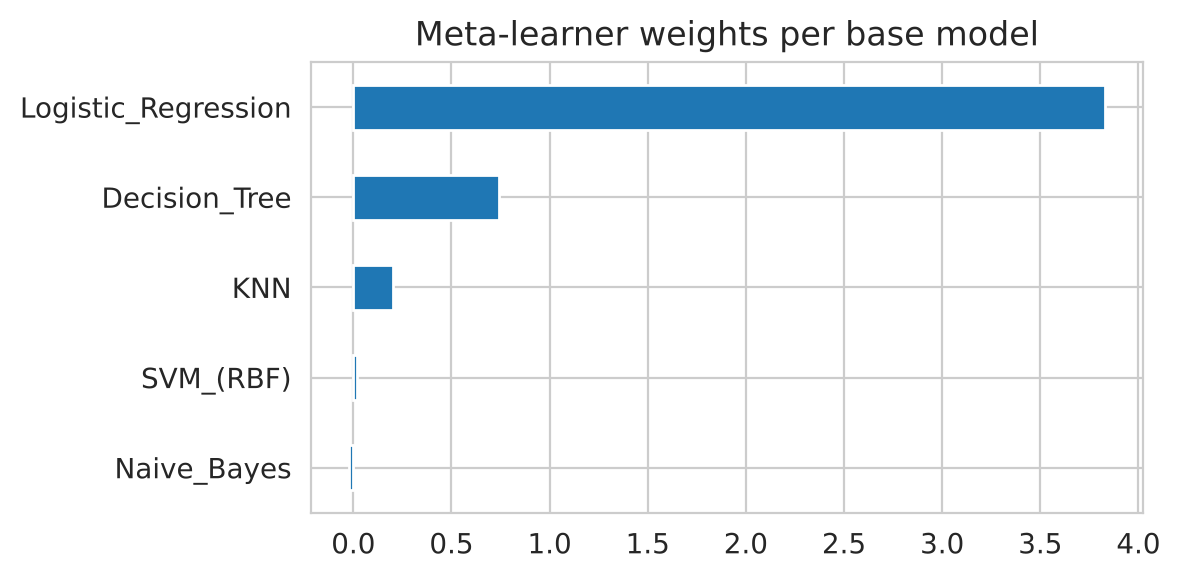

In [16]:
# =============================================================
# STEP 13: EXTRA ANALYSIS - INSIDE ADABOOST AND STACKING
# =============================================================
# (a) AdaBoost: how does test F1 change as more boosting rounds are added?
ada = all_models["AdaBoost (Stump)"]
# apply the fitted preprocessing steps manually, because staged_predict belongs to the AdaBoost step only
Xt_test = ada.named_steps["dense"].transform(ada.named_steps["prep"].transform(X_test))
# staged_predict yields predictions after 1, 2, 3 ... rounds
stage_f1 = [f1_score(y_test, p) for p in ada.named_steps["clf"].staged_predict(Xt_test)]
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(stage_f1) + 1), stage_f1)
plt.xlabel("Number of boosting rounds"); plt.ylabel("Test F1"); plt.title("AdaBoost (stump): F1 vs rounds")
plt.tight_layout(); plt.show()

# (b) Stacking: which base model does the meta-classifier trust most?
stk = all_models["Stacking (meta: LR)"].named_steps["clf"]
# coefficients of the meta Logistic Regression = importance given to each base model's probability
meta_w = pd.Series(stk.final_estimator_.coef_[0], index=[n for n, _ in stk.estimators]).sort_values()
print("Meta-learner (Logistic Regression) coefficients on base-model probabilities:")
print(meta_w.round(3))
meta_w.plot(kind="barh", figsize=(6, 3), title="Meta-learner weights per base model"); plt.tight_layout(); plt.show()

In [17]:
# Detailed per-class report (precision / recall / F1) for the stacking ensemble
print(classification_report(y_test, preds["Stacking (meta: LR)"], target_names=["No churn", "Churn"]))

              precision    recall  f1-score   support

    No churn       0.91      0.67      0.77       817
       Churn       0.32      0.69      0.43       183

    accuracy                           0.67      1000
   macro avg       0.61      0.68      0.60      1000
weighted avg       0.80      0.67      0.71      1000



## Results Analysis

> **Note:** the numbers below come from the run with the *synthetic Telco-style* dataset (5,000 customers, 18.3% churn; 4,000 train / 1,000 test). If you re-run with the real Kaggle Telco CSV placed next to the notebook, the exact values will change; re-read the tables and update this section accordingly.

### 1. Test-set comparison

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression (base) | 0.672 | 0.318 | 0.694 | 0.436 | 0.760 |
| KNN (base) | 0.818 | 0.508 | 0.175 | 0.260 | 0.715 |
| Decision Tree (base) | 0.648 | 0.308 | 0.743 | 0.436 | 0.736 |
| SVM RBF (base) | 0.683 | 0.325 | 0.678 | 0.439 | 0.751 |
| Naive Bayes (base) | 0.729 | 0.346 | 0.541 | 0.422 | 0.714 |
| **Stacking (meta: LR)** | 0.671 | 0.317 | 0.689 | 0.434 | **0.760** |
| AdaBoost (Stump) | 0.584 | 0.247 | 0.623 | 0.354 | 0.668 |
| AdaBoost (Depth-2 Tree) | 0.735 | 0.337 | 0.464 | 0.391 | 0.682 |
| AdaBoost (Logistic Reg.) | 0.672 | 0.311 | 0.650 | 0.420 | 0.718 |
| **Voting (Hard / Majority)** | 0.702 | 0.336 | 0.645 | **0.442** | n/a |
| Voting (Soft) | 0.771 | 0.396 | 0.481 | 0.435 | 0.751 |

### 2. Key observations

- **Accuracy is misleading here.** KNN has the highest accuracy (0.818) but finds only 17.5% of churners (recall 0.175) and has the lowest F1 (0.260). With 81.7% of customers not churning, a model that mostly says "no churn" looks accurate while being useless for retention. F1, Recall and ROC-AUC are the right metrics.
- **Best ensembles on the test set:** Hard voting has the best F1 (0.442) and Stacking has the best ROC-AUC (0.760, tied with Logistic Regression at 0.760). However, the margins over the best base model (SVM F1 = 0.439, Logistic Regression AUC = 0.760) are tiny, about 0.003 in F1.
- **Cross-validation tells the same story.** Hard voting (CV F1 0.472), Stacking (0.471) and Logistic Regression (0.469) are essentially tied, and their differences are far smaller than the fold-to-fold standard deviation (about 0.016-0.018). So on this dataset we **cannot claim** that stacking or voting is significantly better than a well-tuned Logistic Regression.
- **Why the ensembles did not win clearly:** the churn signal in this dataset is dominated by roughly linear effects (contract type, tenure, internet service, payment method) plus noise. A single logistic model already captures most of it. The stacking meta-learner confirms this: it put almost all its weight on Logistic Regression (coefficient 3.83), a little on Decision Tree (0.74) and KNN (0.20), and about zero on SVM and Naive Bayes. Stacking therefore learned to mostly copy the best base model, which is why its scores almost equal Logistic Regression's.
- **AdaBoost underperformed the other ensembles.** With decision stumps it had the lowest AUC (0.668) and F1 (0.354) among the ensembles; deeper trees and a logistic base learner improved it (F1 0.391 and 0.420), but it still did not beat plain Logistic Regression. Boosting is sensitive to label noise because it keeps increasing the weight of hard (often mislabelled/noisy) samples, and this dataset has substantial noise by design.
- **Soft vs hard voting:** Soft voting had higher accuracy and precision (0.771 / 0.396) but lower recall (0.481) than hard voting (0.702 / 0.336 / 0.645). Averaging probabilities lets confident "no churn" models (KNN, Naive Bayes) outweigh the others at the default 0.5 threshold, whereas majority voting caught more churners. Which is better depends on whether a missed churner or a wasted retention offer costs more.
- **Cost:** stacking was the slowest to train (about 7.9 s vs 0.05 s for Logistic Regression) because it trains every base model several times for out-of-fold predictions. Voting cost about the same as its slowest member (SVM), and AdaBoost was cheap.
- **Caveats:** a single 80/20 split, default decision threshold 0.5, no hyper-parameter tuning, and class weights set to "balanced" for most base models. Small metric differences (about 0.01) should not be over-interpreted.

### 3. When to use each ensemble method

| Method | Use it when | Avoid / watch out when |
|---|---|---|
| **Stacking** | You have several *diverse* strong models and want the best possible AUC / ranking quality; the meta-learner also shows which base model matters | Data is small or training time matters; base models are similar (little to learn); risk of leakage if out-of-fold predictions are not used |
| **AdaBoost** | You want to turn weak, simple learners (stumps) into a strong model, features have non-linear interactions, and labels are fairly clean | Labels are noisy or there are many outliers (it over-focuses on them, as seen here); needs more tuning (number of rounds, learning rate) |
| **Voting** | You need a quick, simple, interpretable combination of already-trained models; hard voting for class labels, soft voting when models give calibrated probabilities | Base models are weak or highly correlated (vote adds nothing); one very good model is being out-voted by several mediocre ones |

### 4. Suggestions for further improvement and research

1. Tune hyper-parameters (grid/random/Bayesian search) for every base model, the AdaBoost learning rate and rounds, and the stacking meta-learner.
2. **Tune the decision threshold** (or use a precision-recall curve) according to the business cost of a missed churner versus an unnecessary retention offer, instead of the default 0.5.
3. Handle imbalance more explicitly with SMOTE / under-sampling / cost-sensitive learning and compare with `class_weight`.
4. Add stronger ensembles: Random Forest (bagging), Gradient Boosting, XGBoost, LightGBM, CatBoost, and use them as stacking base learners.
5. Use repeated stratified cross-validation and a statistical test (e.g. paired t-test or McNemar) to check whether differences between models are significant.
6. Engineer features (tenure buckets, charges per month of tenure, service-count features), and add model interpretability with SHAP/permutation importance.
7. Run on the real Telco dataset and on other churn datasets, and check calibration of probabilities (calibration curves) before using soft voting or stacking.

In [18]:
# =============================================================
# SUMMARY: WHICH MODEL IS BEST ON EACH METRIC?
# =============================================================
best_f1  = results["F1-score"].idxmax()                     # idxmax = row label of the maximum value
best_auc = results["ROC-AUC"].idxmax()
best_rec = results["Recall"].idxmax()
print("Data source        :", DATA_SOURCE)
print("Best F1-score      :", best_f1, round(results.loc[best_f1, "F1-score"], 4))
print("Best ROC-AUC       :", best_auc, round(results.loc[best_auc, "ROC-AUC"], 4))
print("Best Recall (churn):", best_rec, round(results.loc[best_rec, "Recall"], 4))

# best individual (non-ensemble) model, for comparison with the ensembles
best_base = results.loc[list(base_models().keys()), "F1-score"].idxmax()
print("Best base model    :", best_base, round(results.loc[best_base, "F1-score"], 4))

Data source        : Synthetic Telco-style churn data (generated in notebook)
Best F1-score      : Voting (Hard / Majority) 0.4419
Best ROC-AUC       : Stacking (meta: LR) 0.7602
Best Recall (churn): Decision Tree 0.7432
Best base model    : SVM (RBF) 0.4389


## Conclusion

In this experiment, stacking, AdaBoost and voting ensembles were implemented in scikit-learn pipelines for customer churn prediction and compared with five base classifiers (Logistic Regression, KNN, Decision Tree, SVM, Naive Bayes) using Accuracy, Precision, Recall, F1 and ROC-AUC, confusion matrices, ROC curves and 5-fold cross-validation.

- **Stacking** (meta-classifier: Logistic Regression) reached the best ROC-AUC (0.760) and a CV F1 of 0.471, but this was essentially equal to the best base model, because the meta-learner relied almost entirely on Logistic Regression.
- **Hard (majority) voting** obtained the best test F1 (0.442) and the best CV F1 (0.472), again only marginally above the best single models.
- **AdaBoost** performed worse than the other ensembles on this noisy dataset (best variant: Logistic Regression base, F1 0.420), showing its sensitivity to noisy labels and its dependence on the choice of weak learner.
- Accuracy alone was misleading on this imbalanced data (KNN: accuracy 0.818 but recall 0.175); F1, Recall and ROC-AUC give a truer picture of churn-detection ability.

The main lesson is that ensembles are not automatically better: they help when the base models are diverse and make different errors, and gain little when a single simple model already captures most of the signal. With tuning, threshold selection, stronger tree-based learners and evaluation on the real Telco data, further gains can be expected. The experiment met its objective of implementing, evaluating and comparing the three ensemble techniques and understanding when each should be used.